[![Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://www.kaggle.com/code/maryrobynbernabe/coral-sound-project-4-testing-best-model)

In [1]:
#load the model
import pickle

model_name = "/kaggle/input/notebooks/maryrobynbernabe/coral-sound-project-3-model-training/rf_best_model.pkl"
file_name = open(model_name, 'rb')
final_model = pickle.load(file_name)
print("Model is loaded")

Model is loaded


In [2]:
import pandas as pd
#read the data file
df_test = pd.read_csv("/kaggle/input/notebooks/maryrobynbernabe/coral-sound-project-2-dataset-splitting/test_set.csv")
df_test.head()

,audio_file_name,RMSE,SPECTRAL_CENTROID,SPECTRAL_BANDWIDTH,ROLLOFF,ZERO_CROSSING_RATE,MFCC_FEATURE_0,MFCC_FEATURE_1,MFCC_FEATURE_2,MFCC_FEATURE_3,...,MFCC_FEATURE_11,MFCC_FEATURE_12,MFCC_FEATURE_13,MFCC_FEATURE_14,MFCC_FEATURE_15,MFCC_FEATURE_16,MFCC_FEATURE_17,MFCC_FEATURE_18,MFCC_FEATURE_19,labels
0,BoF3.1205H.1678278701.180829.3.30.wav,0.013509,2371.907343,3346.767120,6973.074501,0.000383,-581.47125,-31.149992,31.942299,25.752459,...,7.486877,4.100320,9.267488,4.850466,10.294695,5.458443,9.026334,4.239098,8.640108,Healthy
1,BoF5.0532D.671907872.180831.3.14.wav,0.000865,6161.231539,2825.887582,9247.689914,0.452658,-572.35670,-42.258537,24.068690,18.263010,...,6.299976,0.018795,4.825120,1.052692,6.586744,-0.410561,5.983515,0.842368,2.919782,Degraded
2,BaN12.0915H.805322778.180907.5.59.wav,0.010927,3035.079825,3355.987134,7441.117505,0.001610,-533.98660,-40.026726,1.502462,27.008759,...,11.493428,3.216962,9.309798,9.065527,10.811224,5.195178,12.704576,7.134038,8.885212,Healthy
3,BoF4.2333R.805322778.180830.2.6.wav,0.010955,3606.676635,3525.684684,8136.329967,0.002737,-546.04486,-73.790490,2.513496,25.006584,...,13.005180,4.703271,9.324385,7.987784,9.296119,3.120103,10.756012,6.079686,7.576439,Restored
4,BoN11.1103R.1677983769.180906.3.34.wav,0.010840,2845.637586,3484.363955,7609.820651,0.000821,-573.16070,-36.600240,26.502802,21.257563,...,7.846145,4.681725,7.935759,3.057675,9.470773,5.528121,8.262956,2.826576,8.037794,Restored


In [3]:
LABEL_COLUMN = "labels"

In [4]:
LABELS = list(df_test[LABEL_COLUMN].unique())
# sort the labels
LABELS.sort()
print(LABELS)

['Degraded', 'Healthy', 'Restored']


In [5]:
# convert into numbers
df_test[LABEL_COLUMN] = pd.factorize(df_test[LABEL_COLUMN], sort = True)[0]

### Take The Predictions

In [6]:
#getting predictions data
columns_to_drop = ['audio_file_name', LABEL_COLUMN]

test_data_list = df_test.drop(columns=columns_to_drop).values
y_true = df_test[LABEL_COLUMN].values

y_pred = final_model.predict(test_data_list)
print("Predictions: {}".format(y_pred))

Predictions: [1 0 1 2 1 2 1 1 2 0 0 0 2 2 2 1 1 1 1 2 2 2 2 2 2 0 2 0 0 0 2 2 0 2 2 2 2
 0 2 0 1 2 1 0 2 1 1 2 1 0 0 2 1]


### Confusion Matrix & Classification Report

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix


def plot_confusion_matrix(y_true, y_pred, labels):
    # Compute normalized confusion matrix
    cm = confusion_matrix(y_true, y_pred, normalize='true')

    # Convert to percentages
    cm_percentage = cm * 100

    # Create annotations for confusion matrix values with the percentage sign
    annotations = np.array([[f'{val:.2f}%' for val in row] for row in cm_percentage])

    # Plot the confusion matrix
    plt.figure(figsize=(8, 8))
    sns.heatmap(cm_percentage, annot=annotations, annot_kws={"size": 20}, fmt='', cmap="Blues",
                xticklabels=labels, yticklabels=labels)

    plt.title("Normalized Confusion Matrix")
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.show()

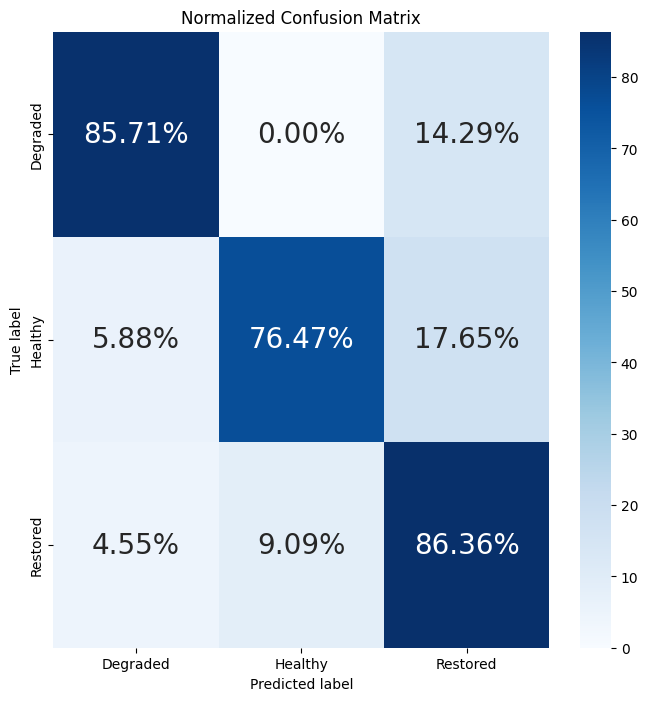

In [8]:
plot_confusion_matrix(y_true, y_pred, LABELS)

In [9]:
#classification reports
from sklearn.metrics import classification_report
print(classification_report(y_true,y_pred))

              precision    recall  f1-score   support

           0       0.86      0.86      0.86        14
           1       0.87      0.76      0.81        17
           2       0.79      0.86      0.83        22

    accuracy                           0.83        53
   macro avg       0.84      0.83      0.83        53
weighted avg       0.83      0.83      0.83        53

